In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("Customers.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (2000, 8)


In [3]:
df.head()

,CustomerID,Gender,Age,Annual Income ($),Spending Score (1-100),Profession,Work Experience,Family Size
0,1,Male,19,15000,39,Healthcare,1,4
1,2,Male,21,35000,81,Engineer,3,3
2,3,Female,20,86000,6,Engineer,1,1
3,4,Female,23,59000,77,Lawyer,0,2
4,5,Female,31,38000,40,Entertainment,2,6


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              2000 non-null   int64
 1   Gender                  2000 non-null   str  
 2   Age                     2000 non-null   int64
 3   Annual Income ($)       2000 non-null   int64
 4   Spending Score (1-100)  2000 non-null   int64
 5   Profession              1965 non-null   str  
 6   Work Experience         2000 non-null   int64
 7   Family Size             2000 non-null   int64
dtypes: int64(6), str(2)
memory usage: 125.1 KB


In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
CustomerID                 0
Gender                     0
Age                        0
Annual Income ($)          0
Spending Score (1-100)     0
Profession                35
Work Experience            0
Family Size                0
dtype: int64


In [6]:
df['Profession'] = df['Profession'].fillna(df['Profession'].mode()[0])

print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [7]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [8]:
features = [
    'Age',
    'Annual Income ($)',
    'Spending Score (1-100)',
    'Work Experience',
    'Family Size'
]

X = df[features]

print("Selected Features:")
print(features)

print("\nFeature Matrix Shape:", X.shape)

Selected Features:
['Age', 'Annual Income ($)', 'Spending Score (1-100)', 'Work Experience', 'Family Size']

Feature Matrix Shape: (2000, 5)


In [9]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")
print("Scaled Data Shape:", X_scaled.shape)

Feature scaling completed!
Scaled Data Shape: (2000, 5)


In [10]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

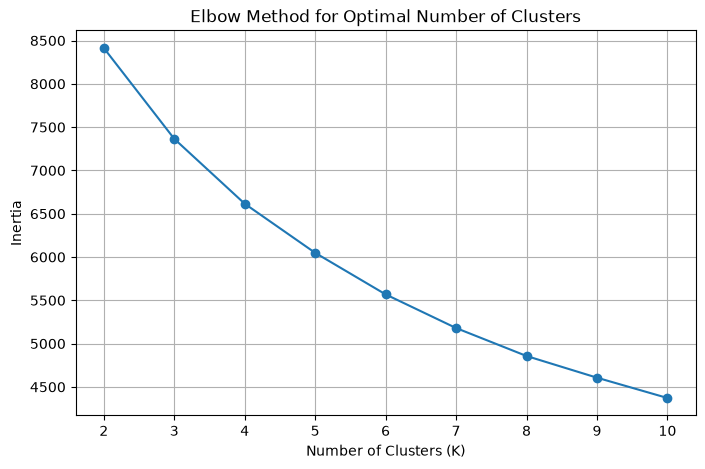

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

Text(0.5, 1.0, 'Elbow Method for Optimal Number of Clusters')

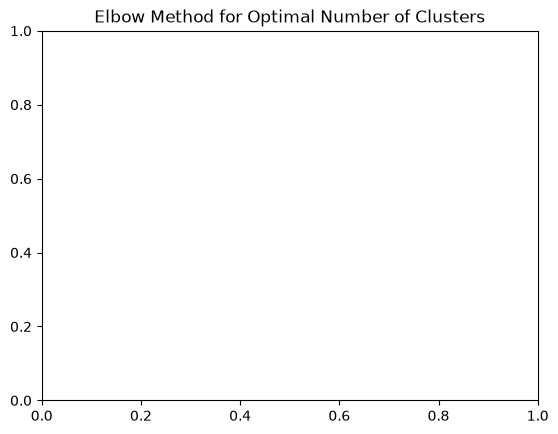

In [12]:
plt.title('Elbow Method for Optimal Number of Clusters')

In [13]:
# Apply K-Means Clustering

optimal_k = 5

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed successfully!")
print("Number of Clusters:", optimal_k)

K-Means clustering completed successfully!
Number of Clusters: 5


In [14]:
# Count customers in each cluster

cluster_counts = df['Cluster'].value_counts().sort_index()

print("Customers in Each Cluster:")
print(cluster_counts)

Customers in Each Cluster:
Cluster
0    384
1    413
2    379
3    407
4    417
Name: count, dtype: int64


In [15]:
# Analyze the characteristics of each customer cluster

cluster_summary = df.groupby('Cluster')[features].mean().round(2)

print("Customer Cluster Summary:")
display(cluster_summary)

Customer Cluster Summary:


,Age,Annual Income ($),Spending Score (1-100),Work Experience,Family Size
Cluster,,,,,
0,32.27,133657.09,46.48,4.26,6.13
1,27.08,98701.66,76.77,3.02,2.60
2,54.27,121610.54,38.22,9.17,2.78
3,80.40,120598.18,67.69,2.83,4.45
4,50.48,82018.42,24.78,1.66,2.98


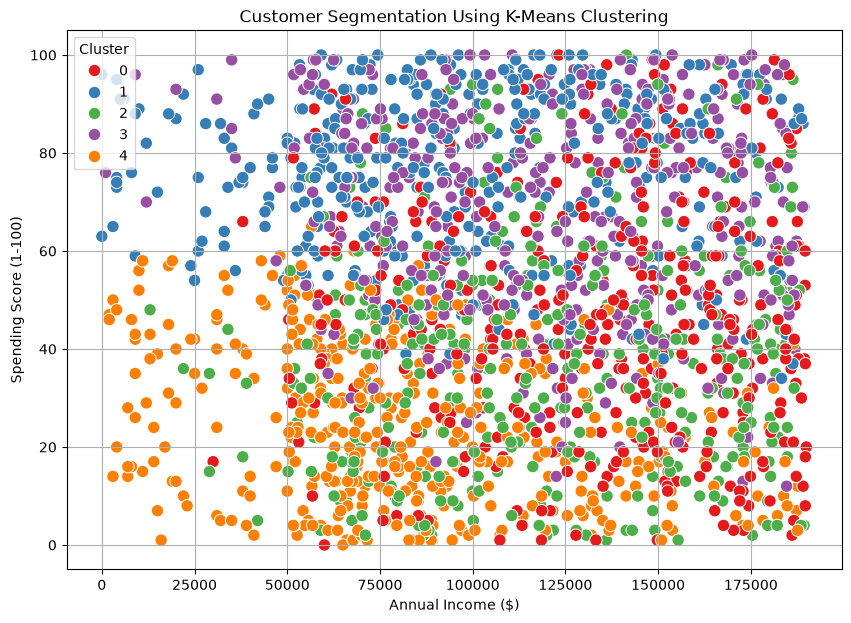

In [16]:
# Visualize Customer Segmentation

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x='Annual Income ($)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set1',
    s=80
)

plt.title('Customer Segmentation Using K-Means Clustering')
plt.xlabel('Annual Income ($)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(True)

plt.show()

In [17]:
# Display detailed cluster characteristics

print("Cluster Characteristics:")
display(cluster_summary)

print("\nCluster Customer Counts:")
display(cluster_counts)

Cluster Characteristics:


,Age,Annual Income ($),Spending Score (1-100),Work Experience,Family Size
Cluster,,,,,
0,32.27,133657.09,46.48,4.26,6.13
1,27.08,98701.66,76.77,3.02,2.60
2,54.27,121610.54,38.22,9.17,2.78
3,80.40,120598.18,67.69,2.83,4.45
4,50.48,82018.42,24.78,1.66,2.98



Cluster Customer Counts:


Cluster
0    384
1    413
2    379
3    407
4    417
Name: count, dtype: int64

In [18]:
# Assign meaningful names to the customer segments

segment_names = {
    0: 'High Income - Medium Spending',
    1: 'Medium Income - High Spending',
    2: 'High Income - Low Spending',
    3: 'High Income - High Spending',
    4: 'Lower Income - Low Spending'
}

df['Segment'] = df['Cluster'].map(segment_names)

print("Customer Segments:")
display(df[['CustomerID', 'Cluster', 'Segment']].head(20))

Customer Segments:


,CustomerID,Cluster,Segment
0,1,4,Lower Income - Low Spending
1,2,1,Medium Income - High Spending
2,3,4,Lower Income - Low Spending
3,4,1,Medium Income - High Spending
4,5,4,Lower Income - Low Spending
5,6,1,Medium Income - High Spending
6,7,4,Lower Income - Low Spending
7,8,1,Medium Income - High Spending
8,9,4,Lower Income - Low Spending
9,10,1,Medium Income - High Spending


In [19]:
# Business Insights from Customer Segmentation

print("BUSINESS INSIGHTS")
print("=" * 50)

print("\n1. High Income - High Spending Customers:")
print("These customers have high income and high spending scores.")
print("They can be considered important customers for premium products and loyalty programs.")

print("\n2. Medium Income - High Spending Customers:")
print("These customers show high spending behavior despite having moderate income.")
print("Targeted offers and personalized promotions can help retain them.")

print("\n3. High Income - Medium Spending Customers:")
print("These customers have high income but moderate spending.")
print("Personalized recommendations may encourage higher engagement.")

print("\n4. High Income - Low Spending Customers:")
print("These customers have high income but relatively low spending.")
print("Special offers and targeted marketing may help increase their spending.")

print("\n5. Lower Income - Low Spending Customers:")
print("These customers have comparatively lower income and low spending.")
print("Budget-friendly products and suitable offers can be targeted to this group.")

BUSINESS INSIGHTS

1. High Income - High Spending Customers:
These customers have high income and high spending scores.
They can be considered important customers for premium products and loyalty programs.

2. Medium Income - High Spending Customers:
These customers show high spending behavior despite having moderate income.
Targeted offers and personalized promotions can help retain them.

3. High Income - Medium Spending Customers:
These customers have high income but moderate spending.
Personalized recommendations may encourage higher engagement.

4. High Income - Low Spending Customers:
These customers have high income but relatively low spending.
Special offers and targeted marketing may help increase their spending.

5. Lower Income - Low Spending Customers:
These customers have comparatively lower income and low spending.
Budget-friendly products and suitable offers can be targeted to this group.


In [20]:
# Save the final customer segmentation dataset

output_file = 'Customer_Segmentation_Final.csv'

df.to_csv(output_file, index=False)

print("Final dataset saved successfully!")
print("File name:", output_file)
print("Final Dataset Shape:", df.shape)

Final dataset saved successfully!
File name: Customer_Segmentation_Final.csv
Final Dataset Shape: (2000, 10)


In [21]:
# Final project verification

print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Total Customers:", len(df))
print("Total Clusters:", df['Cluster'].nunique())

Missing Values: 0
Duplicate Rows: 0
Total Customers: 2000
Total Clusters: 5


In [22]:
# New Customer Input

age = float(input("Enter Age: "))
income = float(input("Enter Annual Income ($): "))
spending_score = float(input("Enter Spending Score (1-100): "))
work_experience = float(input("Enter Work Experience (years): "))
family_size = float(input("Enter Family Size: "))

new_customer = np.array([[
    age,
    income,
    spending_score,
    work_experience,
    family_size
]])

print("\nNew customer data entered successfully!")
print(new_customer)

Enter Age:  25
Enter Annual Income ($):  40000
Enter Spending Score (1-100):  70
Enter Work Experience (years):  3
Enter Family Size:  4



New customer data entered successfully!
[[2.5e+01 4.0e+04 7.0e+01 3.0e+00 4.0e+00]]


In [23]:
# Predict the cluster for the new customer

new_customer_scaled = scaler.transform(new_customer)

predicted_cluster = kmeans.predict(new_customer_scaled)[0]

predicted_segment = segment_names[predicted_cluster]

print("Predicted Cluster:", predicted_cluster)
print("Predicted Customer Segment:", predicted_segment)

Predicted Cluster: 1
Predicted Customer Segment: Medium Income - High Spending


In [24]:
# Predict the cluster for the new customer

new_customer_scaled = scaler.transform(new_customer)

predicted_cluster = kmeans.predict(new_customer_scaled)[0]

predicted_segment = segment_names[predicted_cluster]

print("Predicted Cluster:", predicted_cluster)
print("Predicted Customer Segment:", predicted_segment)

Predicted Cluster: 1
Predicted Customer Segment: Medium Income - High Spending


In [25]:
import joblib

joblib.dump(kmeans, 'kmeans_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Models saved successfully!")

Models saved successfully!
